In [1]:
from helper import get_q_scale_symmetric

In [2]:
import torch

In [3]:
test_tensor=torch.tensor(
    [[191.6, -13.5, 728.6],
     [92.14, 295.5,  -184],
     [0,     684.6, 245.5]]
)

In [4]:
# dim = 0, along the rows
# dim = 1, along the columns

dim=0
output_dim = test_tensor.shape[dim]

In [5]:
output_dim

3

In [6]:
scale = torch.zeros(output_dim)

In [7]:
scale

tensor([0., 0., 0.])

In [8]:
for index in range(output_dim):
    sub_tensor=test_tensor.select(dim,index)
    scale[index]=get_q_scale_symmetric(tensor=sub_tensor)

scale

tensor([5.7370, 2.3268, 5.3906])

In [9]:
scale_shape =[1] * test_tensor.dim()

In [10]:
scale_shape

[1, 1]

In [11]:
scale_shape[dim]= -1
scale_shape

[-1, 1]

In [12]:
scale = scale.view(scale_shape)
scale

tensor([[5.7370],
        [2.3268],
        [5.3906]])

In [13]:
from helper import linear_q_with_scale_and_zero_point

qunatized_tensor=linear_q_with_scale_and_zero_point(test_tensor,scale,0)

In [14]:
qunatized_tensor

tensor([[ 33,  -2, 127],
        [ 40, 127, -79],
        [  0, 127,  46]], dtype=torch.int8)

In [40]:
def linear_q_symmetric_per_channel(r_tensor, dim , dtype=torch.int8):
    output_dim = r_tensor.shape[dim]

    scale = torch.zeros(output_dim)
    print(scale)
    for index in range(output_dim):
        sub_teor=r_tensor.select(dim,index)
        print(sub_tensor)
        scale[index]=get_q_scale_symmetric(tensor=sub_tensor,dtype=dtype)
        print(scale)

        

    scale_shape=[1] * r_tensor.dim()
    scale_shape[dim] = -1
    scale = scale.view(scale_shape)

    quantized_tensor=linear_q_with_scale_and_zero_point(r_tensor,scale=scale, zero_point=0, dtype=dtype)

    return quantized_tensor, scale
        

In [41]:
test_tensor=torch.tensor(
    [[191.6, -13.5, 728.6],
     [92.14, 295.5,  -184],
     [0,     684.6, 245.5]]
)

In [42]:
### along the rows (dim = 0)
quantized_tensor_0, scale_0 = linear_q_symmetric_per_channel(
    test_tensor, dim=0)

### along the columns (dim = 1)
quantized_tensor_1, scale_1 = linear_q_symmetric_per_channel(
    test_tensor, dim=1)

tensor([0., 0., 0.])
tensor([  0.0000, 684.6000, 245.5000])
tensor([5.3906, 0.0000, 0.0000])
tensor([  0.0000, 684.6000, 245.5000])
tensor([5.3906, 5.3906, 0.0000])
tensor([  0.0000, 684.6000, 245.5000])
tensor([5.3906, 5.3906, 5.3906])
tensor([0., 0., 0.])
tensor([  0.0000, 684.6000, 245.5000])
tensor([5.3906, 0.0000, 0.0000])
tensor([  0.0000, 684.6000, 245.5000])
tensor([5.3906, 5.3906, 0.0000])
tensor([  0.0000, 684.6000, 245.5000])
tensor([5.3906, 5.3906, 5.3906])


In [32]:
print(scale_0)

tensor([[5.3906],
        [5.3906],
        [5.3906]])


In [33]:
print(scale_1)

tensor([[5.3906, 5.3906, 5.3906]])


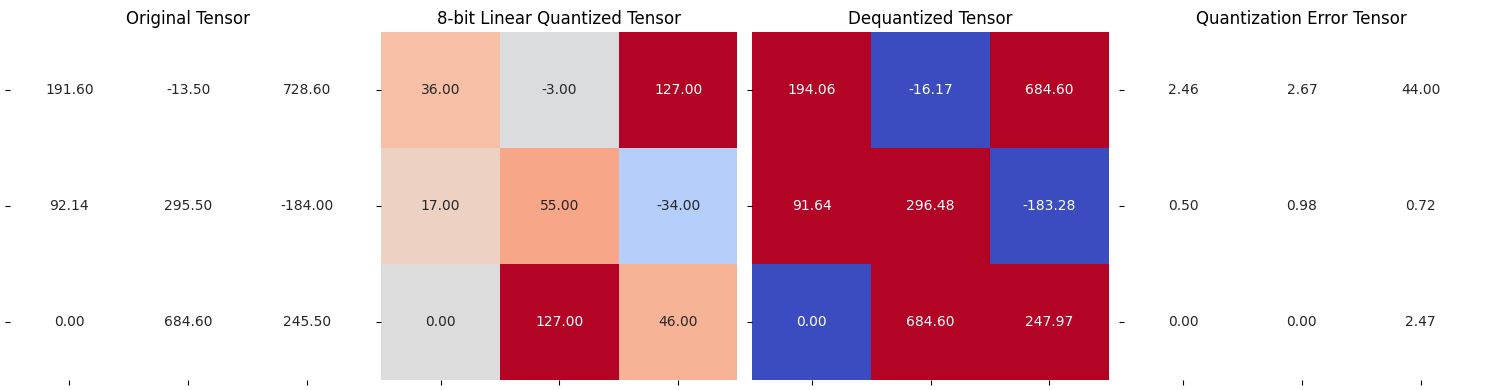

In [29]:
from helper import linear_dequantization , plot_quantization_errors, quantization_error

dequantized_tensor_0 = linear_dequantization(
    quantized_tensor_0, scale_0, 0)

plot_quantization_errors(
    test_tensor, quantized_tensor_0, dequantized_tensor_0)

In [30]:
print(f"""Quantization Error : \
{quantization_error(test_tensor, dequantized_tensor_0)}""")

Quantization Error : 217.44427490234375


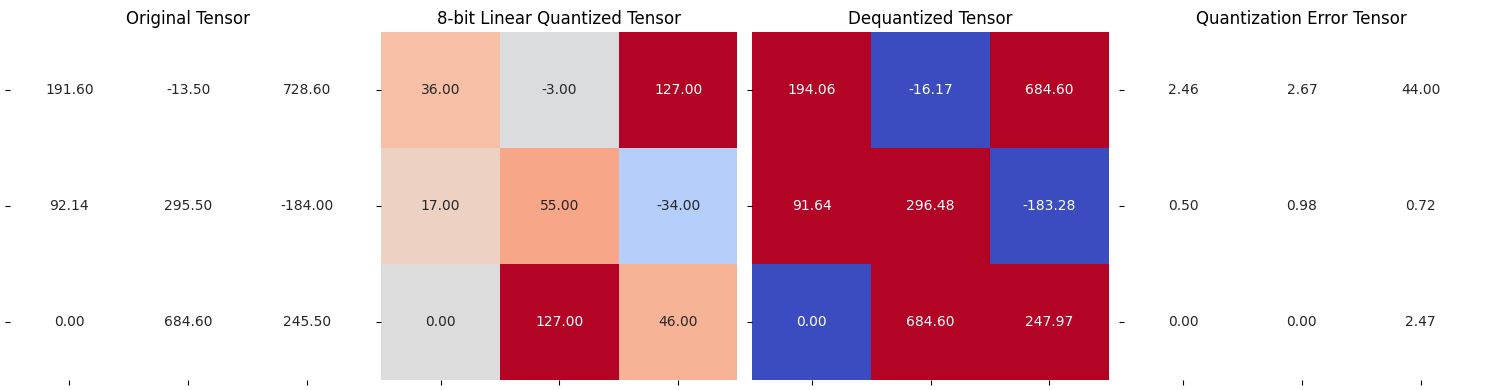

Quantization Error : 217.44427490234375


In [31]:
dequantized_tensor_1 = linear_dequantization(
    quantized_tensor_1, scale_1, 0)

plot_quantization_errors(
    test_tensor, quantized_tensor_1, dequantized_tensor_1, n_bits=8)

print(f"""Quantization Error : \
{quantization_error(test_tensor, dequantized_tensor_1)}""")